## Model 5: Random Forest Regressor (Ensemble)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [21]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split

In [22]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### 3. Base Model Training (Default 100 Trees)

In [23]:
base_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
base_rf.fit(X_train, y_train)

y_train_base = base_rf.predict(X_train)
y_test_base = base_rf.predict(X_test)

### 4. Base Model Evaluation Metrics (Train & Test)

In [24]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base Random Forest Metrics:")
display(base_metrics)

Base Random Forest Metrics:


,Train Set,Test Set
MAE,0.9779,2.5865
MSE,2.4295,16.3724
RMSE,1.5587,4.0463
R2,0.9823,0.8764


### 5. Hyperparameter Tuning (300 Trees, Depth 22, max_features 0.8)

In [25]:
# Tuning tree count, max depth and subsampling features to decorrelate trees
tuned_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=22,
    min_samples_split=4,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)
tuned_rf.fit(X_train, y_train)

print("Changed Parameters:      ", {'n_estimators': 300, 'max_depth': 22, 'min_samples_split': 4, 'max_features': 0.8})

Changed Parameters:       {'n_estimators': 300, 'max_depth': 22, 'min_samples_split': 4, 'max_features': 0.8}


### 6. Tuned Model Evaluation Metrics (Train & Test)

In [26]:
y_train_tuned = tuned_rf.predict(X_train)
y_test_tuned = tuned_rf.predict(X_test)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned Random Forest Metrics:")
display(tuned_metrics)

Tuned Random Forest Metrics:


,Train Set,Test Set
MAE,1.1177,2.5798
MSE,3.0643,16.0990
RMSE,1.7505,4.0124
R2,0.9777,0.8785


### 7. Comparison: Base vs Tuned & R2 Increase

In [27]:
rf_comparison = pd.DataFrame({
    'Base RF (100 trees)': base_metrics['Test Set'],
    'Tuned RF (300 trees)': tuned_metrics['Test Set']
})
display(rf_comparison)

base_r2 = base_metrics.loc['R2', 'Test Set']
tuned_r2 = tuned_metrics.loc['R2', 'Test Set']
diff_r2 = tuned_r2 - base_r2

print(f"Base Test R2:          {base_r2:.4f}")
print(f"Tuned Test R2:         {tuned_r2:.4f}")
print(f"Increase in R2 Score:  {diff_r2:+.4f}")
print(f"Test MAE dropped to:   {tuned_metrics.loc['MAE', 'Test Set']:.4f} mg/m³")

,Base RF (100 trees),Tuned RF (300 trees)
MAE,2.5865,2.5798
MSE,16.3724,16.0990
RMSE,4.0463,4.0124
R2,0.8764,0.8785


Base Test R2:          0.8764
Tuned Test R2:         0.8785
Increase in R2 Score:  +0.0021
Test MAE dropped to:   2.5798 mg/m³


### 8. Plots: Feature Importances & Predicted vs Actual

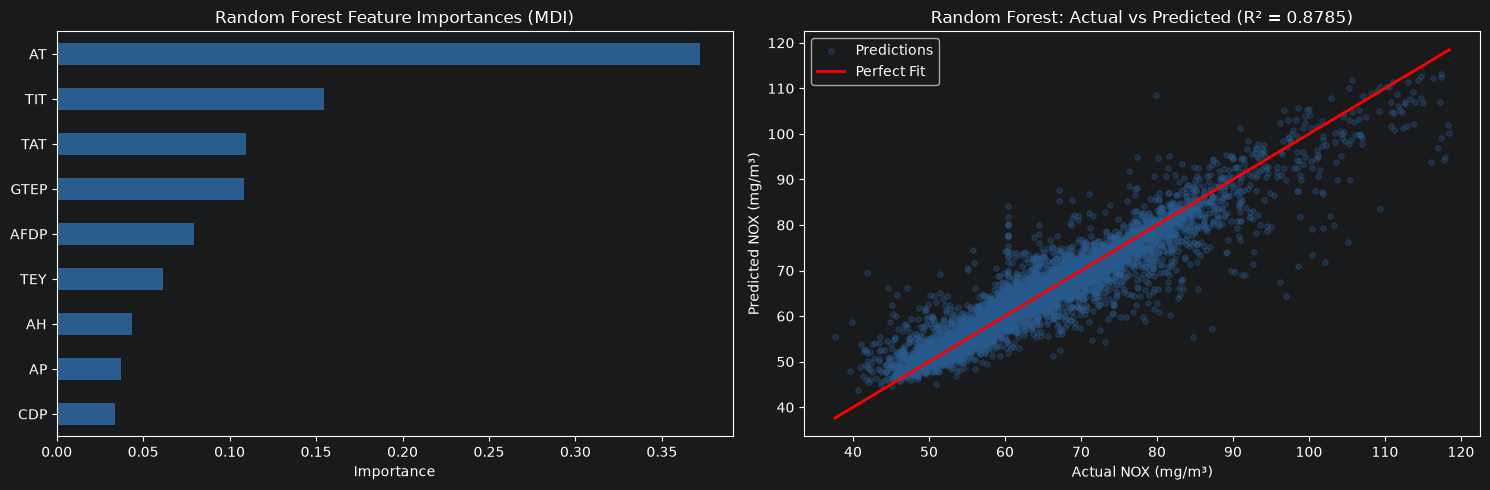

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Feature importances
feat_imp = pd.Series(tuned_rf.feature_importances_, index=X.columns).sort_values(ascending=True)
feat_imp.plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title("Random Forest Feature Importances (MDI)")
axes[0].set_xlabel("Importance")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_tuned, color='#2b5c8f', alpha=0.3, s=15, label='Predictions')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')
axes[1].set_title(f"Random Forest: Actual vs Predicted (R² = {tuned_r2:.4f})")
axes[1].set_xlabel("Actual NOX (mg/m³)")
axes[1].set_ylabel("Predicted NOX (mg/m³)")
axes[1].legend()

plt.tight_layout()
plt.show()